In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


df = pd.read_csv('/kaggle/input/datasets/shambhurajejagadale/student-performance-prediction-dataset/student_dataset_10000_rows.csv')
print("--- Dataset Summary ---")
print(df.info())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Summary Statistics ---")
print(df.describe())



--- Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  object 
dtypes: float64(1), int64(6), object(1)
memory usage: 625.1+ KB
None

--- Missing Values ---
study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64

--- Summary Statistics ---

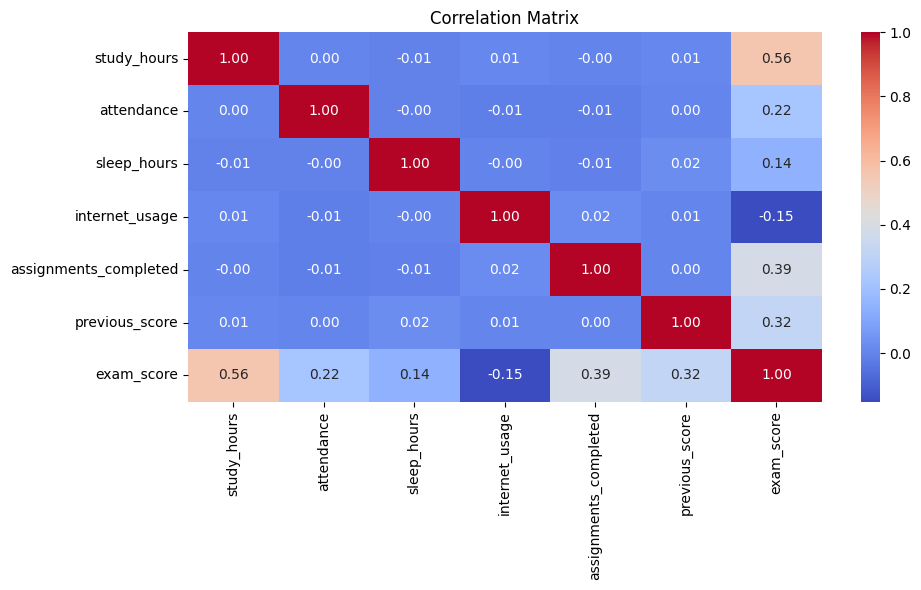

Features after polynomial expansion: 45

--- Scikit-Learn Polynomial Regression Performance ---
MSE: 39.0759
RMSE: 6.2511
MAE: 4.7900
R2 Score: 0.8299


In [14]:
# Visualizations
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

df = df.drop_duplicates()


df['study_attendance_prod'] = df['study_hours'] * df['attendance']
df['rest_study_ratio'] = df['sleep_hours'] / (df['study_hours'] + 1e-5)

X = df.drop(columns=['exam_score'])
y = df['exam_score']

num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object']).columns.tolist()

# Polynomial degree (2 = quadratic, 3 = cubic, ...)
DEGREE = 2

# Polynomial expansion BEFORE scaling, so the new features are standardized too
num_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=DEGREE, include_bias=False)),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', OneHotEncoder(drop='first'), cat_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
print("Features after polynomial expansion:", X_train_scaled.shape[1])

lr_model = LinearRegression()  # linear model on polynomial features = Polynomial Regression
lr_model.fit(X_train_scaled, y_train)


y_pred = lr_model.predict(X_test_scaled)
print("\n--- Scikit-Learn Polynomial Regression Performance ---")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")

In [15]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_squared_error, r2_score

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

class PolynomialRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(PolynomialRegressionModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)

input_dim = X_train_tensor.shape[1]
print(f"Detected input_dim (features after polynomial expansion): {input_dim}")

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)

model = PolynomialRegressionModel(input_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

model.eval()
with torch.no_grad():
    predictions = model(X_test_tensor).numpy()

print("--- Adam Optimizer Performance (Polynomial Regression, degree={}) ---".format(DEGREE))
print(f"MSE: {mean_squared_error(y_test, predictions):.4f}")
print(f"R2 Score: {r2_score(y_test, predictions):.4f}")

Detected input_dim (features after polynomial expansion): 45
--- Adam Optimizer Performance (Polynomial Regression, degree=2) ---
MSE: 51.8763
R2 Score: 0.7742


m1=0.5487, m2=-0.0991, c=0.1158, final cost=0.3380


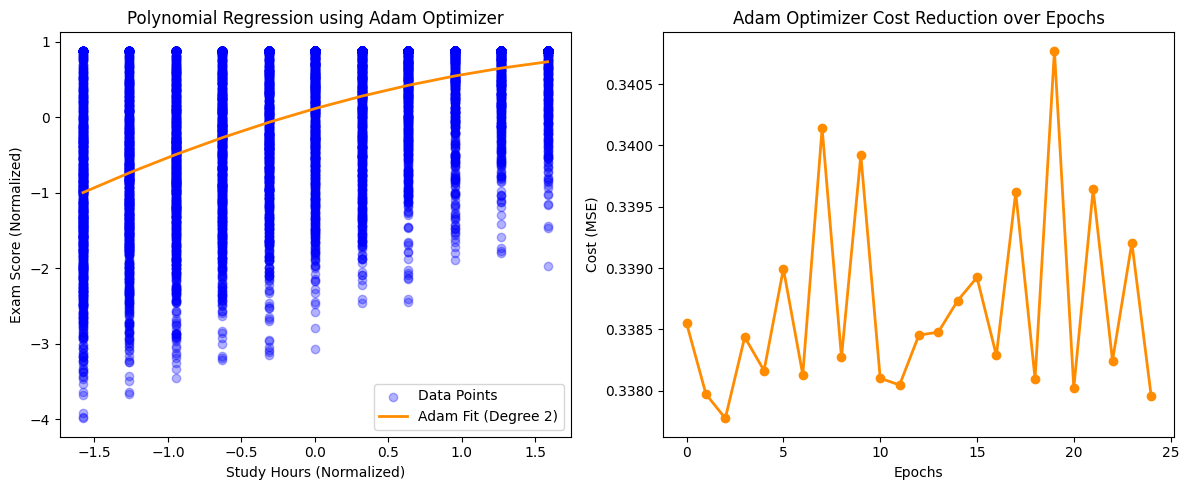

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

X = df["study_hours"].values
y = df["exam_score"].values

# Normalization
X_norm = (X - np.mean(X)) / np.std(X)
y_norm = (y - np.mean(y)) / np.std(y)

# Polynomial feature (X^2)
X_poly = X_norm**2

# Parameters: y = m1*X + m2*X^2 + c
m1 = 0.0
m2 = 0.0
c = 0.0
L = 0.01
epochs = 25
batch_size = 64
n = len(X_norm)
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
mo_m1, mo_m2, mo_c = 0.0, 0.0, 0.0
v_m1, v_m2, v_c = 0.0, 0.0, 0.0
t = 0

cost_history = []

for epoch in range(epochs):
  indices = np.arange(n)
  np.random.shuffle(indices)
  X_shuffled = X_norm[indices]
  Xp_shuffled = X_poly[indices]
  y_shuffled = y_norm[indices]

  for i in range(0, n, batch_size):
    X_batch = X_shuffled[i : i + batch_size]
    Xp_batch = Xp_shuffled[i : i + batch_size]
    y_batch = y_shuffled[i : i + batch_size]
    curr_batch_size = len(X_batch)
    t += 1

    y_pred = m1 * X_batch + m2 * Xp_batch + c

    D_m1 = (2 / curr_batch_size) * np.sum((y_pred - y_batch) * X_batch)
    D_m2 = (2 / curr_batch_size) * np.sum((y_pred - y_batch) * Xp_batch)
    D_c = (2 / curr_batch_size) * np.sum(y_pred - y_batch)

    mo_m1 = beta1 * mo_m1 + (1 - beta1) * D_m1
    mo_m2 = beta1 * mo_m2 + (1 - beta1) * D_m2
    mo_c = beta1 * mo_c + (1 - beta1) * D_c

    v_m1 = beta2 * v_m1 + (1 - beta2) * (D_m1**2)
    v_m2 = beta2 * v_m2 + (1 - beta2) * (D_m2**2)
    v_c = beta2 * v_c + (1 - beta2) * (D_c**2)

    mo_m1_hat = mo_m1 / (1 - beta1**t)
    mo_m2_hat = mo_m2 / (1 - beta1**t)
    mo_c_hat = mo_c / (1 - beta1**t)
    v_m1_hat = v_m1 / (1 - beta2**t)
    v_m2_hat = v_m2 / (1 - beta2**t)
    v_c_hat = v_c / (1 - beta2**t)

    m1 = m1 - (L / (np.sqrt(v_m1_hat) + epsilon)) * mo_m1_hat
    m2 = m2 - (L / (np.sqrt(v_m2_hat) + epsilon)) * mo_m2_hat
    c = c - (L / (np.sqrt(v_c_hat) + epsilon)) * mo_c_hat

  y_pred_all = m1 * X_norm + m2 * X_poly + c
  epoch_cost = (1 / (2 * n)) * np.sum((y_pred_all - y_norm) ** 2)
  cost_history.append(epoch_cost)

print(f"m1={m1:.4f}, m2={m2:.4f}, c={c:.4f}, final cost={cost_history[-1]:.4f}")

# Plot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_norm, y_norm, color="blue", alpha=0.3, label="Data Points")
sort_idx = np.argsort(X_norm)
X_sorted = X_norm[sort_idx]
y_pred_sorted = m1 * X_sorted + m2 * (X_sorted**2) + c
plt.plot(X_sorted, y_pred_sorted, color="darkorange", linewidth=2, label="Adam Fit (Degree 2)")
plt.xlabel("Study Hours (Normalized)")
plt.ylabel("Exam Score (Normalized)")
plt.title("Polynomial Regression using Adam Optimizer")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epochs), cost_history, color="darkorange", marker="o", linewidth=2)
plt.xlabel("Epochs")
plt.ylabel("Cost (MSE)")
plt.title("Adam Optimizer Cost Reduction over Epochs")

plt.tight_layout()
plt.show()